### Importing Required Libraries

In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("C:/Users/Admin/Downloads/framingham new.csv")

In [4]:
df.head()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


In [5]:
df.tail()

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0
4237,0,52,2.0,0,0.0,0.0,0,0,0,269.0,133.5,83.0,21.47,80.0,107.0,0
4238,1,40,3.0,0,0.0,0.0,0,1,0,185.0,141.0,98.0,25.60,67.0,72.0,0
4239,0,39,3.0,1,30.0,0.0,0,0,0,196.0,133.0,86.0,20.91,85.0,80.0,0


In [6]:
df.shape

(4240, 16)

In [7]:
df.columns

Index(['male', 'age', 'education', 'currentSmoker', 'cigsPerDay', 'BPMeds',
       'prevalentStroke', 'prevalentHyp', 'diabetes', 'totChol', 'sysBP',
       'diaBP', 'BMI', 'heartRate', 'glucose', 'TenYearCHD'],
      dtype='str')

In [8]:
df.rename(columns={
    'male':'Gender',
    'age':'Age',
    'education':'Education_Level',
    'currentSmoker':'Current_Smoker',
    'cigsPerDay':'Cigarettes_Per_Day',
    'BPMeds':'BP_Medication',
    'prevalentStroke':'Previous_Stroke',
    'prevalentHyp':'Hypertension',
    'diabetes':'Diabetes',
    'totChol':'Total_Cholesterol',
    'sysBP':'Systolic_BP',
    'diaBP':'Diastolic_BP',
    'BMI':'Body_Mass_Index',
    'heartRate':'Heart_Rate',
    'glucose':'Blood_Sugar_Level',
    'TenYearCHD':'Ten_Year_CHD_Risk'
}, inplace = True)

In [9]:
df.columns

Index(['Gender', 'Age', 'Education_Level', 'Current_Smoker',
       'Cigarettes_Per_Day', 'BP_Medication', 'Previous_Stroke',
       'Hypertension', 'Diabetes', 'Total_Cholesterol', 'Systolic_BP',
       'Diastolic_BP', 'Body_Mass_Index', 'Heart_Rate', 'Blood_Sugar_Level',
       'Ten_Year_CHD_Risk'],
      dtype='str')

### Separating the features columns and Target columns

In [10]:
# Independent Variables are stored in X
X = df.drop('Ten_Year_CHD_Risk', axis = 1)

# Dependent Target column is stored in Y
y = df['Ten_Year_CHD_Risk']

In [11]:
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (4240, 15)
Target Shape: (4240,)


In [12]:
X.head()

,Gender,Age,Education_Level,Current_Smoker,Cigarettes_Per_Day,BP_Medication,Previous_Stroke,Hypertension,Diabetes,Total_Cholesterol,Systolic_BP,Diastolic_BP,Body_Mass_Index,Heart_Rate,Blood_Sugar_Level
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0


In [13]:
y.head()

0    0
1    0
2    0
3    1
4    0
Name: Ten_Year_CHD_Risk, dtype: int64

### Splitting into training and testing data

In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)                                                    

In [15]:
# Independent Feature column shape after splitting
print("Original Shape:",X.shape) 
print("Training Shape:",X_train.shape)
print("Testing Shape:",X_test.shape)

Original Shape: (4240, 15)
Training Shape: (3392, 15)
Testing Shape: (848, 15)


In [16]:
# Dependent Target column shape after splitting
print("Original Shape:",y.shape)
print("Training Shape:",y_train.shape)
print("Testing Shape:",y_test.shape)

Original Shape: (4240,)
Training Shape: (3392,)
Testing Shape: (848,)


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Gender              4240 non-null   int64  
 1   Age                 4240 non-null   int64  
 2   Education_Level     4135 non-null   float64
 3   Current_Smoker      4240 non-null   int64  
 4   Cigarettes_Per_Day  4211 non-null   float64
 5   BP_Medication       4187 non-null   float64
 6   Previous_Stroke     4240 non-null   int64  
 7   Hypertension        4240 non-null   int64  
 8   Diabetes            4240 non-null   int64  
 9   Total_Cholesterol   4190 non-null   float64
 10  Systolic_BP         4240 non-null   float64
 11  Diastolic_BP        4240 non-null   float64
 12  Body_Mass_Index     4221 non-null   float64
 13  Heart_Rate          4239 non-null   float64
 14  Blood_Sugar_Level   3852 non-null   float64
 15  Ten_Year_CHD_Risk   4240 non-null   int64  
dtypes: float64(9), in

In [18]:
# Checking for missing values
df.isnull().sum()

Gender                  0
Age                     0
Education_Level       105
Current_Smoker          0
Cigarettes_Per_Day     29
BP_Medication          53
Previous_Stroke         0
Hypertension            0
Diabetes                0
Total_Cholesterol      50
Systolic_BP             0
Diastolic_BP            0
Body_Mass_Index        19
Heart_Rate              1
Blood_Sugar_Level     388
Ten_Year_CHD_Risk       0
dtype: int64

In [19]:
# Checking for missing values in training dataset
print("Training missing values:")
X_train.isnull().sum()

Training missing values:


Gender                  0
Age                     0
Education_Level        82
Current_Smoker          0
Cigarettes_Per_Day     23
BP_Medication          44
Previous_Stroke         0
Hypertension            0
Diabetes                0
Total_Cholesterol      37
Systolic_BP             0
Diastolic_BP            0
Body_Mass_Index        18
Heart_Rate              1
Blood_Sugar_Level     321
dtype: int64

In [20]:
# Checking for missing values in testing dataset
print("Testing missing values:")
X_test.isnull().sum()

Testing missing values:


Gender                 0
Age                    0
Education_Level       23
Current_Smoker         0
Cigarettes_Per_Day     6
BP_Medication          9
Previous_Stroke        0
Hypertension           0
Diabetes               0
Total_Cholesterol     13
Systolic_BP            0
Diastolic_BP           0
Body_Mass_Index        1
Heart_Rate             0
Blood_Sugar_Level     67
dtype: int64

In [21]:
from sklearn.impute import SimpleImputer

In [22]:
# Median Imputation on numerical columns
numerical_cols = [
    'Total_Cholesterol',
    'Body_Mass_Index',
    'Heart_Rate',
    'Blood_Sugar_Level'
]

median_imputer = SimpleImputer(strategy='median')
X_train[numerical_cols] = median_imputer.fit_transform(
    X_train[numerical_cols]
)
X_test[numerical_cols] = median_imputer.transform(
    X_test[numerical_cols]
)

In [23]:
# Mode Imputation on numerical columns
categorical_cols = [
    'Education_Level',
    'BP_Medication'
]
mode_imputer = SimpleImputer(strategy='most_frequent')
X_train[categorical_cols] = mode_imputer.fit_transform(
    X_train[categorical_cols]
)
X_test[categorical_cols] = mode_imputer.transform(
    X_test[categorical_cols]
)

In [24]:
# Calculating median cigarettes 
median_cigs = X_train.loc[
    X_train['Current_Smoker'] == 1,
    'Cigarettes_Per_Day'
].median()

In [25]:
X_train.loc[
    (X_train['Current_Smoker'] == 0) &
    (X_train['Cigarettes_Per_Day'].isna()),
    'Cigarettes_Per_Day'
] = 0
X_train.loc[
    (X_train['Current_Smoker'] == 1) &
    (X_train['Cigarettes_Per_Day'].isna()),
    'Cigarettes_Per_Day'
] = median_cigs

In [26]:
X_test.loc[
    (X_test['Current_Smoker'] == 0) &
    (X_test['Cigarettes_Per_Day'].isna()),
    'Cigarettes_Per_Day'
] = 0
X_test.loc[
    (X_test['Current_Smoker'] == 1) &
    (X_test['Cigarettes_Per_Day'].isna()),
    'Cigarettes_Per_Day'
] = median_cigs

In [27]:
print("Training missing values:", X_train.isnull().sum().sum())
print("Testing missing values:", X_test.isnull().sum().sum())

Training missing values: 0
Testing missing values: 0


### Checking for outliers

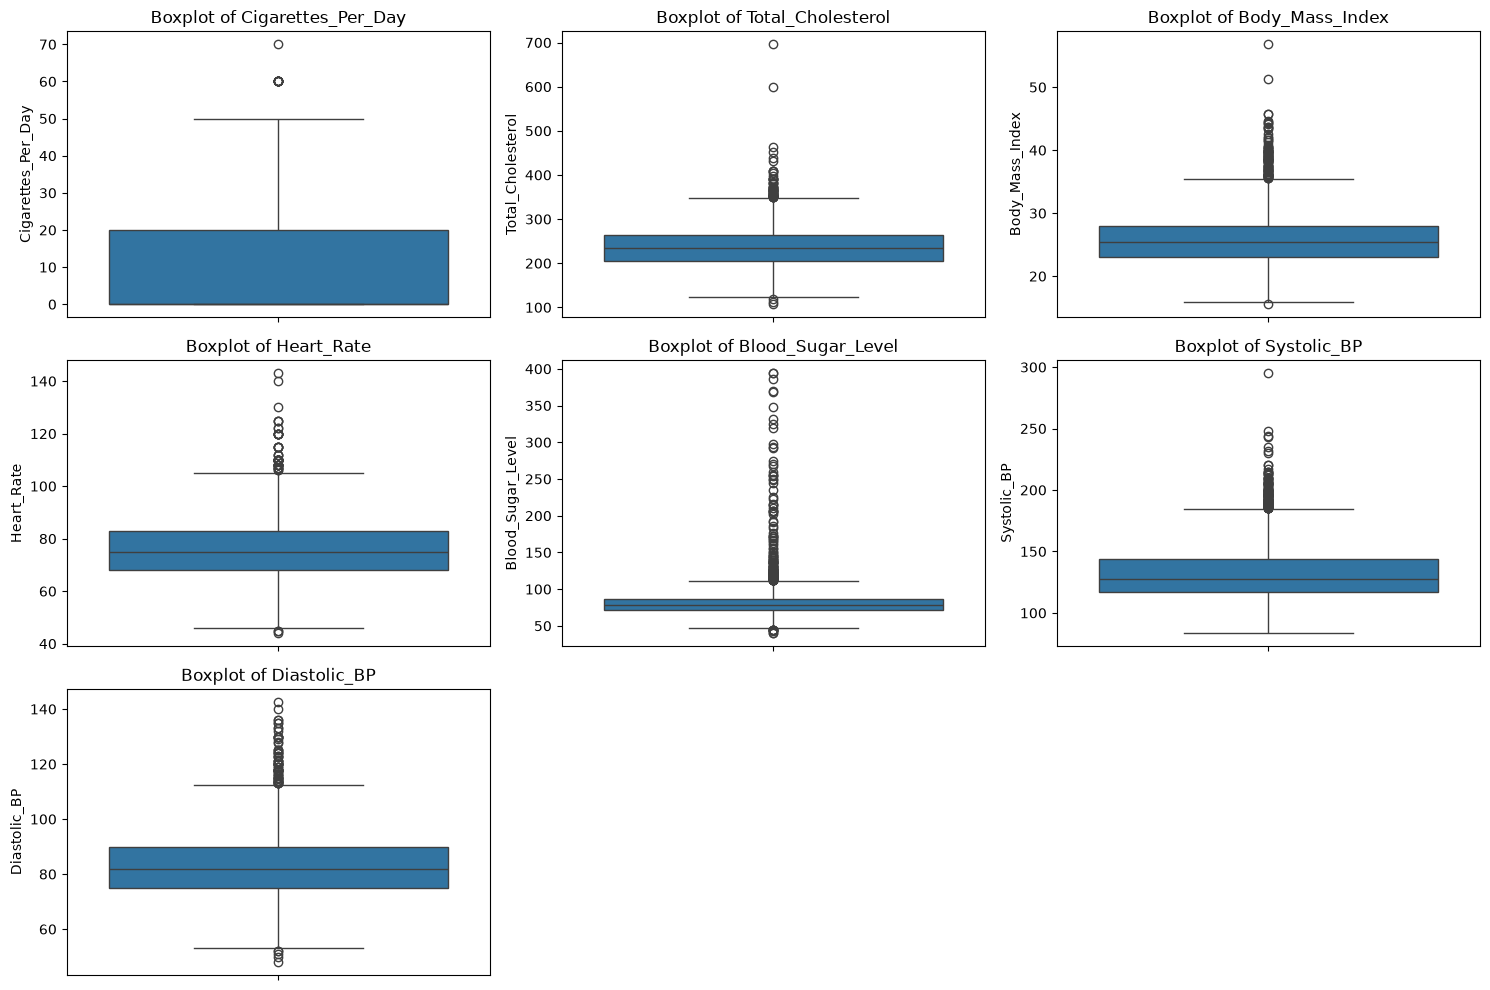

In [28]:
numerical_columns = [
    "Cigarettes_Per_Day",
    "Total_Cholesterol",
    "Body_Mass_Index",
    "Heart_Rate",
    "Blood_Sugar_Level",
    "Systolic_BP",
    "Diastolic_BP"
]
plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_columns):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)
plt.tight_layout()
plt.show()

In [29]:
df.describe()

,Gender,Age,Education_Level,Current_Smoker,Cigarettes_Per_Day,BP_Medication,Previous_Stroke,Hypertension,Diabetes,Total_Cholesterol,Systolic_BP,Diastolic_BP,Body_Mass_Index,Heart_Rate,Blood_Sugar_Level,Ten_Year_CHD_Risk
count,4240.000000,4240.000000,4135.000000,4240.000000,4211.000000,4187.000000,4240.000000,4240.000000,4240.000000,4190.000000,4240.000000,4240.000000,4221.000000,4239.000000,3852.000000,4240.000000
mean,0.429245,49.580189,1.979444,0.494104,9.005937,0.029615,0.005896,0.310613,0.025708,236.699523,132.354599,82.897759,25.800801,75.878981,81.963655,0.151887
std,0.495027,8.572942,1.019791,0.500024,11.922462,0.169544,0.076569,0.462799,0.158280,44.591284,22.033300,11.910394,4.079840,12.025348,23.954335,0.358953
min,0.000000,32.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,107.000000,83.500000,48.000000,15.540000,44.000000,40.000000,0.000000
25%,0.000000,42.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,206.000000,117.000000,75.000000,23.070000,68.000000,71.000000,0.000000
50%,0.000000,49.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,234.000000,128.000000,82.000000,25.400000,75.000000,78.000000,0.000000
75%,1.000000,56.000000,3.000000,1.000000,20.000000,0.000000,0.000000,1.000000,0.000000,263.000000,144.000000,90.000000,28.040000,83.000000,87.000000,0.000000
max,1.000000,70.000000,4.000000,1.000000,70.000000,1.000000,1.000000,1.000000,1.000000,696.000000,295.000000,142.500000,56.800000,143.000000,394.000000,1.000000


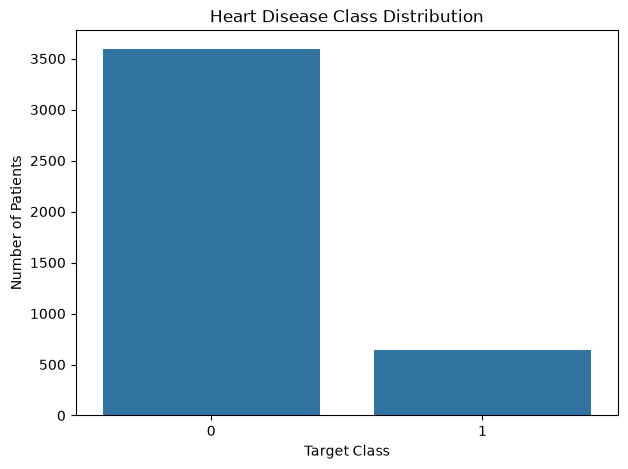

In [30]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x='Ten_Year_CHD_Risk')
plt.title('Heart Disease Class Distribution')
plt.xlabel('Target Class')
plt.ylabel('Number of Patients')
plt.show()

In [31]:
(df["Ten_Year_CHD_Risk"].value_counts())

Ten_Year_CHD_Risk
0    3596
1     644
Name: count, dtype: int64

### Handling Imbalanced data using SMOTE

In [32]:
categorical_cols = [
    'Gender',
    'Education_Level',
    'Current_Smoker',
    'BP_Medication',
    'Previous_Stroke',
    'Hypertension',
    'Diabetes'
] 
numerical_cols = [
    'Age',
    'Cigarettes_Per_Day',
    'Total_Cholesterol',
    'Systolic_BP',
    'Diastolic_BP',
    'Body_Mass_Index',
    'Heart_Rate',
    'Blood_Sugar_Level'
] 
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', 'passthrough', categorical_cols)
    ],
    verbose_feature_names_out=False
)

# SMOTENC categorical feature positions
cat_indices = list(
    range(
        len(numerical_cols),
        len(numerical_cols) + len(categorical_cols)
    )
)

### Performing Scaling

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [34]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200,random_state=42),
    "SVM": SVC(probability=True,random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

In [35]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC
from sklearn.metrics import accuracy_score

trained_models = {}
results = []

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),

        ('smote', SMOTENC(
            categorical_features=cat_indices,
            random_state=42
        )),

        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    y_pred = pipeline.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(name, "Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 67.1 %
Decision Tree Accuracy: 70.4 %
Random Forest Accuracy: 79.13 %


C:\Users\Admin\AppData\Roaming\Python\Python314\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Accuracy: 68.75 %
Gradient Boosting Accuracy: 72.05 %


In [36]:
from sklearn.metrics import classification_report

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print(classification_report(y_test, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.91      0.68      0.78       719
           1       0.25      0.60      0.36       129

    accuracy                           0.67       848
   macro avg       0.58      0.64      0.57       848
weighted avg       0.81      0.67      0.71       848


Decision Tree
              precision    recall  f1-score   support

           0       0.86      0.78      0.82       719
           1       0.19      0.28      0.22       129

    accuracy                           0.70       848
   macro avg       0.52      0.53      0.52       848
weighted avg       0.76      0.70      0.73       848


Random Forest
              precision    recall  f1-score   support

           0       0.87      0.88      0.88       719
           1       0.30      0.27      0.28       129

    accuracy                           0.79       848
   macro avg       0.58      0.58      0.58       848
weighted avg       0.78

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

comparison = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    comparison.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df.sort_values(
    by="ROC AUC",
    ascending=False
)

print(comparison_df.round(4))

                 Model  Accuracy  Precision  Recall  F1 Score  ROC AUC
0  Logistic Regression    0.6710     0.2549  0.6047    0.3586   0.6977
3                  SVM    0.6875     0.2444  0.5039    0.3291   0.6617
4    Gradient Boosting    0.7205     0.2300  0.3566    0.2796   0.6511
2        Random Forest    0.7913     0.2966  0.2713    0.2834   0.6411
1        Decision Tree    0.7040     0.1856  0.2791    0.2229   0.5297


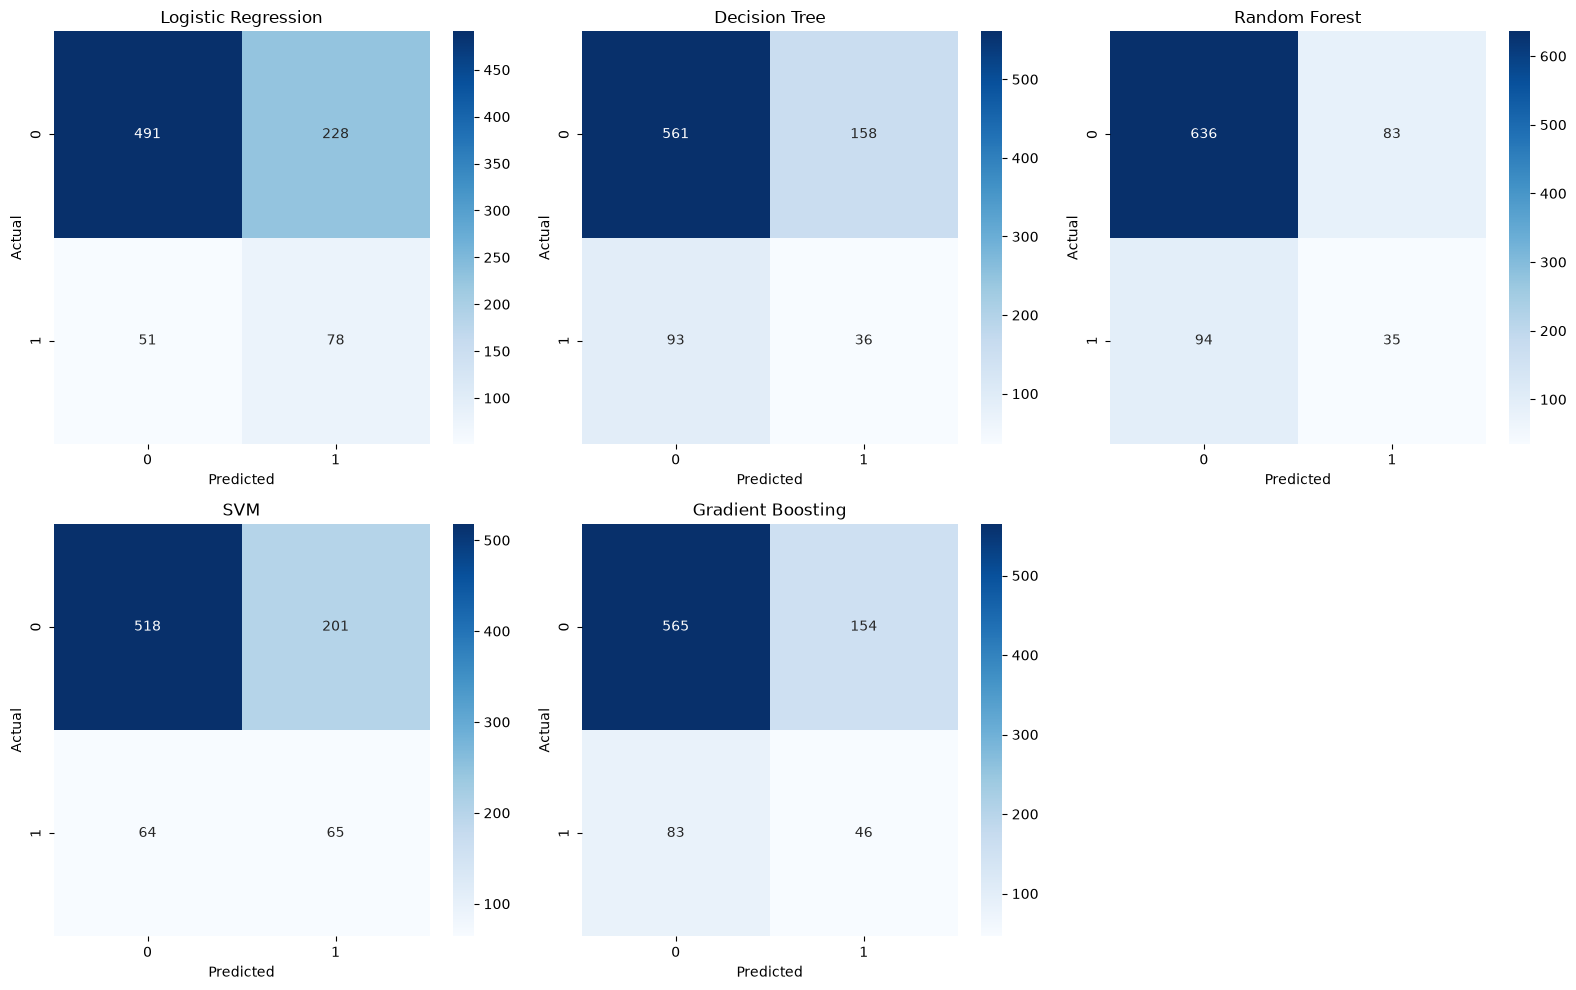

In [38]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, model) in zip(axes.flatten(), trained_models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
fig.delaxes(axes.flatten()[len(trained_models)])
plt.tight_layout()
plt.show()

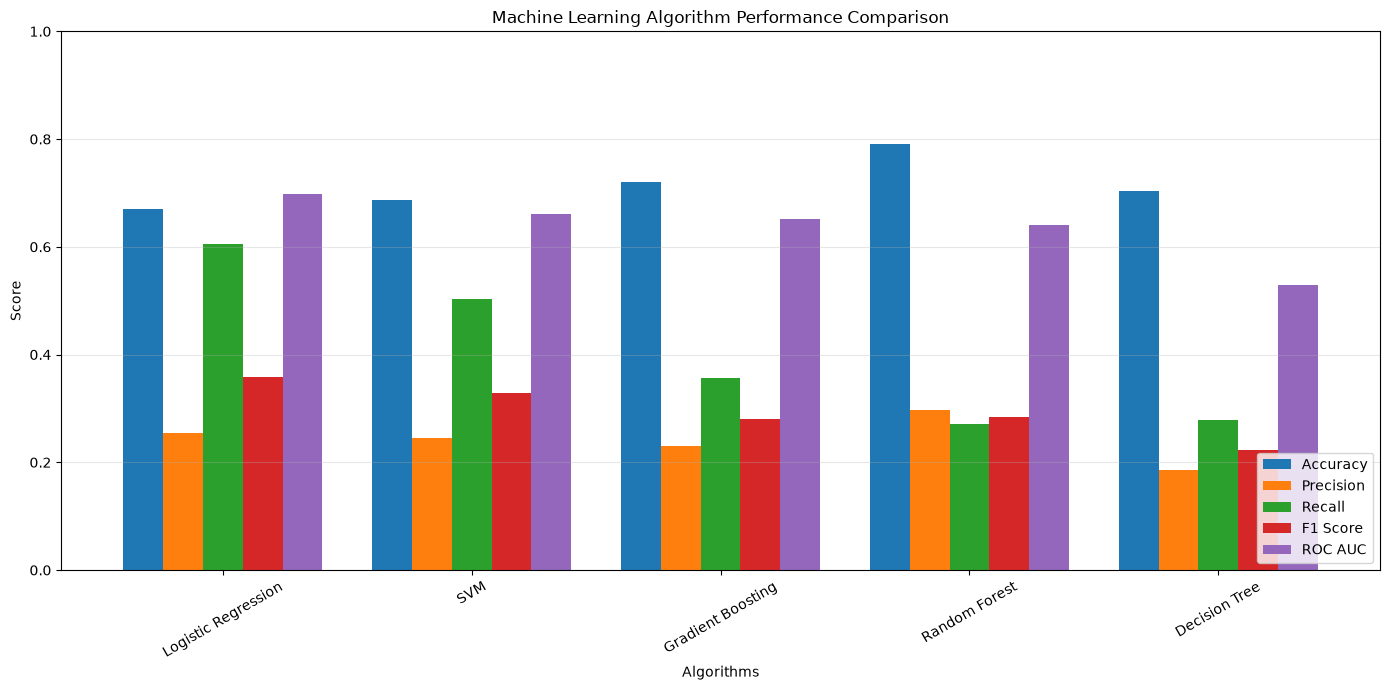

In [39]:
comparison_plot = comparison_df.set_index("Model")

comparison_plot.plot(kind="bar", figsize=(14, 7), width=0.8)
plt.title("Machine Learning Algorithm Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Algorithms")
plt.xticks(rotation=30)
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [41]:
import joblib

# Save all trained models and supporting information
model_artifacts = {
    "models": trained_models,
    "comparison": comparison_df,
    "numerical_imputer": median_imputer,
    "categorical_imputer": mode_imputer,
    "median_cigs": median_cigs,
    "numerical_cols": numerical_cols,
    "categorical_cols": categorical_cols,
    "feature_columns": X.columns.tolist(),
    "dataset": df,
    "X_test": X_test,
    "y_test": y_test
}

joblib.dump(
    model_artifacts,
    "coronary_heart_disease_models.pkl"
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [42]:
import os
print(os.getcwd())

C:\Users\Admin\E342\My Python
